# ReservoirScope – IND320 Compulsory Assignment Part 3

This notebook documents Part 3 of the ReservoirScope project.

The work focuses on:

- geographical reservoir regions from NVE shapefiles,
- random sampling of locations within each region,
- historical ERA5 weather data from the Open-Meteo API,
- precipitation outlier detection using DCT and Statistical Process Control,
- temperature anomaly detection using Local Outlier Factor,
- STL decomposition of reservoir filling levels,
- spectrogram analysis,
- and integration of these analyses into the Streamlit application.

In [1]:
# Import libraries for geographical data handling,
# numerical analysis, plotting, and file inspection.
from pathlib import Path

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

In [2]:
# Define the folder containing the downloaded NVE shapefiles
# and inspect the available files before loading the geographical data.
shapefile_dir = Path("../data/shapefiles")

files = list(shapefile_dir.rglob("*"))

for file in files:
    print(file)

../data/shapefiles/elspotomraader.geojson
../data/shapefiles/nve_regions.geojson


In [3]:
# Identify all shapefile layers available in the NVE data folder.
shp_files = list(
    shapefile_dir.rglob("*.shp")
)

print("Number of shapefiles:", len(shp_files))

for file in shp_files:
    print(file)

Number of shapefiles: 0


In [4]:
# Load the NVE electricity bidding-area polygons.
elspot_path = shapefile_dir / "elspotomraader.geojson"

elspot_gdf = gpd.read_file(elspot_path)

print("Columns:")
print(elspot_gdf.columns)

print("\nCRS:")
print(elspot_gdf.crs)

print("\nElectricity areas:")
print(
    sorted(
        elspot_gdf["ElSpotOmr"]
        .dropna()
        .unique()
    )
)

Columns:
Index(['OBJECTID', 'ElSpotOmr', 'GlobalID', 'ORIG_FID', 'Shape.STArea()',
       'Shape.STLength()', 'geometry'],
      dtype='str')

CRS:
EPSG:4326

Electricity areas:
['NO1', 'NO2', 'NO3', 'NO4', 'NO5']


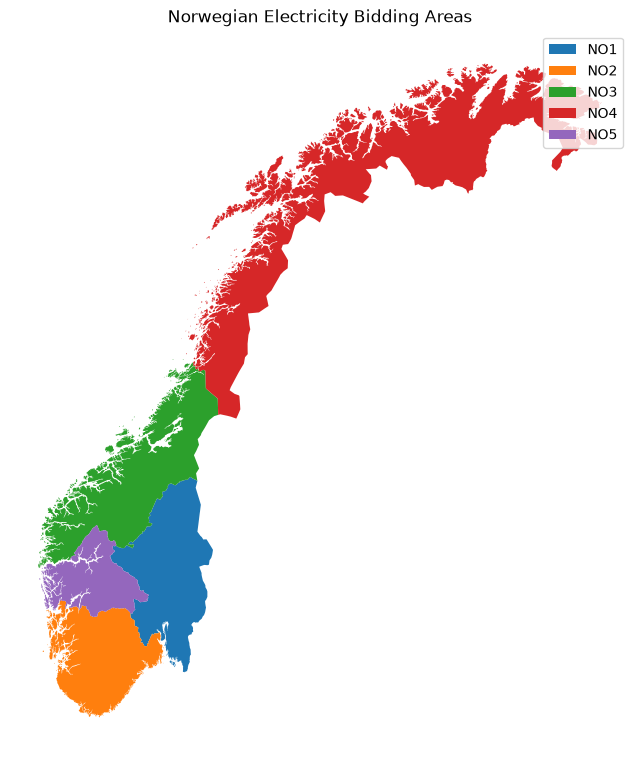

In [5]:
# Plot the electricity bidding areas to verify that
# the downloaded NVE polygons were loaded correctly.
elspot_gdf.plot(
    column="ElSpotOmr",
    legend=True,
    figsize=(8, 10)
)

plt.title("Norwegian Electricity Bidding Areas")
plt.axis("off")
plt.show()

## Geographical Regions for Weather Sampling

The Part 3 assignment requires weather data to be sampled from geographical
regions corresponding to the Magasinstatistikk areas.

Two types of regions are relevant:

- electricity bidding areas, such as NO1–NO5,
- precipitation/reservoir regions used for Magasinstatistikk.

The electricity-area polygons are loaded from NVE's `ELSpottomraader`
geographical layer.

The precipitation-region layer will be identified separately because the
assignment specifies that East is represented by `RS + RØ` and North by
`RM + RN`.

In [6]:
# Inspect the number of polygons and region labels
# in the NVE electricity-area dataset.
print("Number of polygons:", len(elspot_gdf))

print(
    elspot_gdf[
        ["ElSpotOmr"]
    ].drop_duplicates().sort_values("ElSpotOmr")
)

Number of polygons: 5
  ElSpotOmr
2       NO1
0       NO2
3       NO3
4       NO4
1       NO5


### Electricity Bidding Areas

The NVE electricity-area dataset contains five polygons corresponding to
the Norwegian bidding zones:

- NO1
- NO2
- NO3
- NO4
- NO5

These polygons will later be used for random geographic sampling and
weather-data retrieval.

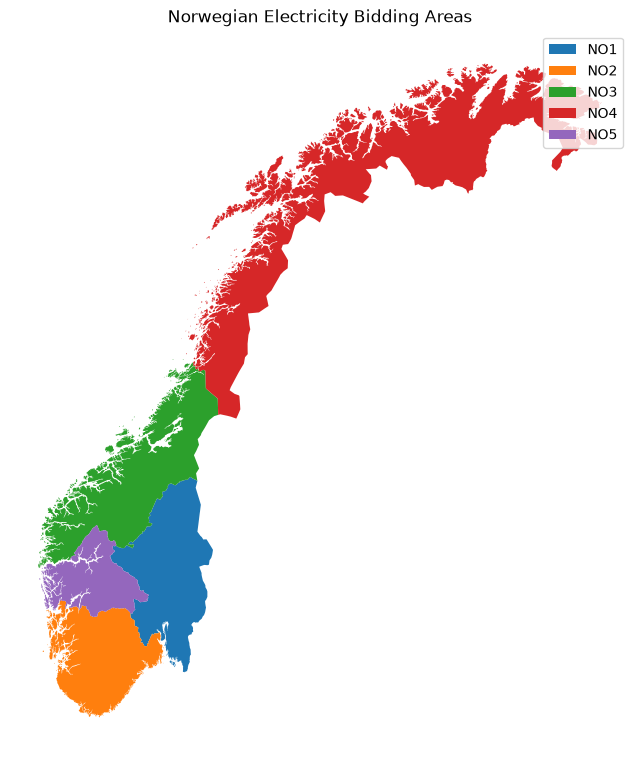

In [7]:
# Visualise the five Norwegian electricity bidding areas.
elspot_gdf.plot(
    column="ElSpotOmr",
    legend=True,
    figsize=(8, 10)
)

plt.title("Norwegian Electricity Bidding Areas")
plt.axis("off")
plt.show()

In [8]:
# Load the NVE regional polygons used to construct
# the broader weather regions for Magasinstatistikk.
region_path = shapefile_dir / "nve_regions.geojson"

region_gdf = gpd.read_file(region_path)

print("Columns:")
print(region_gdf.columns)

print("\nCRS:")
print(region_gdf.crs)

print("\nRegion codes:")
print(
    region_gdf[
        ["REGION", "REGIONNAVN"]
    ].sort_values("REGION")
)

Columns:
Index(['Shape.STArea()', 'Shape.STLength()', 'OBJECTID', 'REGION',
       'REGIONNAVN', 'POSTNUMMER', 'POSTSTED', 'BESØKSADR', 'ADRESSE',
       'geometry'],
      dtype='str')

CRS:
EPSG:4326

Region codes:
  REGION         REGIONNAVN
1     RM  Region Midt-Norge
2     RN        Region Nord
4     RS         Region Sør
0     RV        Region Vest
3     RØ         Region Øst


In [9]:
# Map the five NVE regions to the three broader regions
# required for weather sampling in the assignment.
weather_region_map = {
    "RS": "East",
    "RØ": "East",
    "RV": "West",
    "RM": "North",
    "RN": "North",
}

region_gdf["weather_region"] = (
    region_gdf["REGION"]
    .map(weather_region_map)
)

region_gdf[
    ["REGION", "REGIONNAVN", "weather_region"]
].sort_values("REGION")

,REGION,REGIONNAVN,weather_region
1,RM,Region Midt-Norge,North
2,RN,Region Nord,North
4,RS,Region Sør,East
0,RV,Region Vest,West
3,RØ,Region Øst,East


In [10]:
# Merge the five NVE regions into the three broader
# geographical regions used for weather sampling.
weather_regions_gdf = (
    region_gdf
    .dissolve(by="weather_region")
    .reset_index()
)

print(
    weather_regions_gdf[
        ["weather_region"]
    ]
)

  weather_region
0           East
1          North
2           West


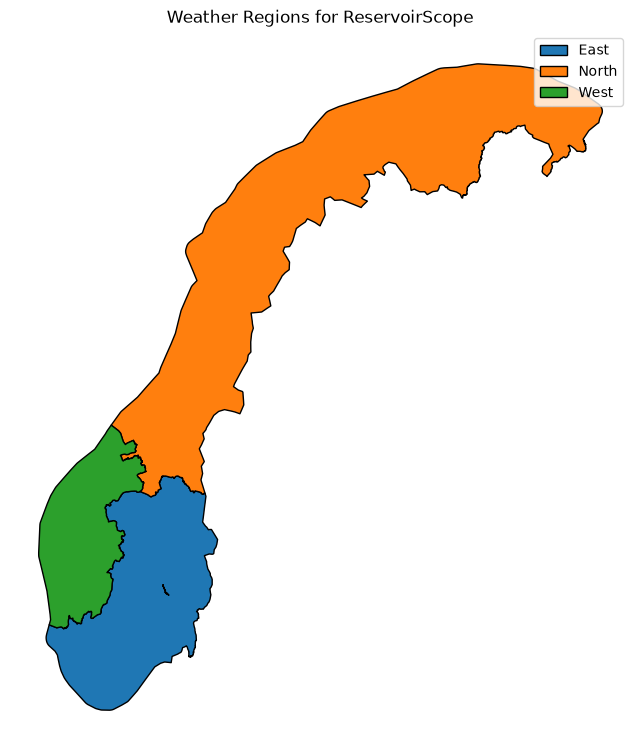

In [11]:
# Visualise the three broader weather regions
# before randomly sampling geographical locations.
weather_regions_gdf.plot(
    column="weather_region",
    legend=True,
    figsize=(8, 10),
    edgecolor="black"
)

plt.title("Weather Regions for ReservoirScope")
plt.axis("off")
plt.show()

In [12]:
# Project the weather-region polygons to ETRS89 / UTM zone 33N
# so random point sampling is performed in metres rather than degrees.
weather_regions_projected = (
    weather_regions_gdf
    .to_crs(epsg=25833)
)

print(weather_regions_projected.crs)

EPSG:25833


In [13]:
# Randomly sample a specified number of points inside a polygon.
# A fixed random seed is used so the sampling is reproducible.
import numpy as np
from shapely.geometry import Point


def sample_points_in_polygon(
    polygon,
    n_points=1000,
    random_seed=42
):
    rng = np.random.default_rng(random_seed)

    min_x, min_y, max_x, max_y = polygon.bounds

    points = []

    while len(points) < n_points:

        x = rng.uniform(min_x, max_x)
        y = rng.uniform(min_y, max_y)

        point = Point(x, y)

        if polygon.contains(point):
            points.append(point)

    return points

In [14]:
# Generate 1000 random locations inside each weather region.
sampled_regions = []

for index, row in weather_regions_projected.iterrows():

    region_name = row["weather_region"]

    points = sample_points_in_polygon(
        polygon=row.geometry,
        n_points=1000,
        random_seed=42 + index
    )

    region_points = gpd.GeoDataFrame(
        {
            "weather_region": [region_name] * len(points)
        },
        geometry=points,
        crs=weather_regions_projected.crs
    )

    sampled_regions.append(region_points)


sampled_points_gdf = pd.concat(
    sampled_regions,
    ignore_index=True
)

sampled_points_gdf = gpd.GeoDataFrame(
    sampled_points_gdf,
    geometry="geometry",
    crs=weather_regions_projected.crs
)

print(
    sampled_points_gdf[
        "weather_region"
    ].value_counts()
)

weather_region
East     1000
North    1000
West     1000
Name: count, dtype: int64


In [15]:
# Convert the sampled points back to WGS84 latitude/longitude
# because the Open-Meteo API expects geographic coordinates.
sampled_points_wgs84 = sampled_points_gdf.to_crs(epsg=4326)

sampled_points_wgs84["longitude"] = sampled_points_wgs84.geometry.x
sampled_points_wgs84["latitude"] = sampled_points_wgs84.geometry.y

sampled_points_wgs84.head()

,weather_region,geometry,longitude,latitude
0,East,POINT (10.98599 60.0238),10.985988,60.023804
1,East,POINT (11.59371 61.28368),11.593705,61.283683
2,East,POINT (10.65407 61.68348),10.654069,61.683476
3,East,POINT (9.55129 61.82063),9.551289,61.820628
4,East,POINT (8.32609 58.89564),8.326093,58.895640


In [16]:
# Confirm that each broader region still contains 1000 sampled locations.
print(
    sampled_points_wgs84[
        "weather_region"
    ].value_counts()
)

weather_region
East     1000
North    1000
West     1000
Name: count, dtype: int64


In [17]:
# Store the sampled longitude/latitude pairs by region
# so they can be passed to the weather-download function.
region_coordinates = {}

for region_name in sampled_points_wgs84["weather_region"].unique():

    region_df = sampled_points_wgs84[
        sampled_points_wgs84["weather_region"] == region_name
    ]

    region_coordinates[region_name] = list(
        zip(
            region_df["longitude"],
            region_df["latitude"]
        )
    )

for region_name, coordinates in region_coordinates.items():
    print(
        region_name,
        len(coordinates),
        coordinates[:3]
    )

East 1000 [(10.985987590196608, 60.02380353263818), (11.593705221333071, 61.283683204932906), (10.654069049999165, 61.68347561761898)]
North 1000 [(30.348252559331815, 70.08930308196052), (13.140701162557653, 64.95433442118961), (13.434418760652095, 67.52723155108127)]
West 1000 [(4.935151281911819, 60.51875560650939), (5.053026893490224, 60.85941179161045), (7.611579487513542, 62.178566831008496)]


In [18]:
import json

# Save sampled broad weather-region coordinates for Streamlit.
with open(
    "../data/weather_region_coordinates.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        region_coordinates,
        file
    )

print("Saved weather_region_coordinates.json")

Saved weather_region_coordinates.json


In [19]:
# Save the sampled coordinates for reproducible reuse
# in the notebook and Streamlit application.
sampled_points_wgs84[
    [
        "weather_region",
        "longitude",
        "latitude"
    ]
].to_csv(
    "../data/weather_region_sample_points.csv",
    index=False
)

## Open-Meteo Historical Weather Data

Historical hourly weather data are retrieved from the Open-Meteo
Historical Weather API using the ERA5 reanalysis model.

The download function takes a weather-region identifier and a time
interval as input. It looks up the sampled longitude/latitude pairs for
that region and retrieves at least:

- temperature at 2 metres,
- precipitation.

The function is tested for the NO3-related weather region for 2024.

In [20]:
# Import requests for API communication and time for
# small pauses between batched Open-Meteo requests.
import requests
import time

In [21]:
# Project the electricity bidding-area polygons to a metric CRS
# before randomly sampling locations inside each area.
elspot_projected = (
    elspot_gdf
    .to_crs(epsg=25833)
)

print(elspot_projected.crs)

EPSG:25833


In [22]:
# Generate 1000 random locations inside each Norwegian
# electricity bidding area (NO1-NO5).
sampled_elspot_regions = []

for index, row in elspot_projected.iterrows():

    area_name = row["ElSpotOmr"]

    points = sample_points_in_polygon(
        polygon=row.geometry,
        n_points=1000,
        random_seed=100 + index
    )

    area_points = gpd.GeoDataFrame(
        {
            "region_identifier": [area_name] * len(points)
        },
        geometry=points,
        crs=elspot_projected.crs
    )

    sampled_elspot_regions.append(area_points)


sampled_elspot_gdf = pd.concat(
    sampled_elspot_regions,
    ignore_index=True
)

sampled_elspot_gdf = gpd.GeoDataFrame(
    sampled_elspot_gdf,
    geometry="geometry",
    crs=elspot_projected.crs
)

print(
    sampled_elspot_gdf[
        "region_identifier"
    ].value_counts().sort_index()
)

region_identifier
NO1    1000
NO2    1000
NO3    1000
NO4    1000
NO5    1000
Name: count, dtype: int64


In [23]:
# Convert the sampled electricity-area locations to WGS84
# coordinates for use with the Open-Meteo API.
sampled_elspot_wgs84 = (
    sampled_elspot_gdf
    .to_crs(epsg=4326)
)

sampled_elspot_wgs84["longitude"] = (
    sampled_elspot_wgs84.geometry.x
)

sampled_elspot_wgs84["latitude"] = (
    sampled_elspot_wgs84.geometry.y
)

sampled_elspot_wgs84.head()

,region_identifier,geometry,longitude,latitude
0,NO2,POINT (10.37554 59.59263),10.375541,59.592625
1,NO2,POINT (8.9276 58.52119),8.927596,58.521193
2,NO2,POINT (8.42008 59.47022),8.420084,59.470222
3,NO2,POINT (8.276 59.34877),8.276000,59.348773
4,NO2,POINT (9.26224 59.29379),9.262242,59.293788


In [24]:
# Store the longitude/latitude pairs for each electricity area.
elspot_coordinates = {}

for area_name in sampled_elspot_wgs84["region_identifier"].unique():

    area_df = sampled_elspot_wgs84[
        sampled_elspot_wgs84["region_identifier"] == area_name
    ]

    elspot_coordinates[area_name] = list(
        zip(
            area_df["longitude"],
            area_df["latitude"]
        )
    )

for area_name, coordinates in elspot_coordinates.items():
    print(
        area_name,
        len(coordinates)
    )

NO2 1000
NO5 1000
NO1 1000
NO3 1000
NO4 1000


In [25]:
import json

# Save sampled electricity-area coordinates for Streamlit.
with open(
    "../data/elspot_coordinates.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        elspot_coordinates,
        file
    )

print("Saved elspot_coordinates.json")

Saved elspot_coordinates.json


In [26]:
# Download historical ERA5 weather data for sampled locations
# while handling Open-Meteo rate limits with retries and backoff.
def download_weather_data(
    region_identifier,
    start_date,
    end_date,
    batch_size=100,
    coordinates_dict=None,
    max_retries=6
):
    if coordinates_dict is None:
        coordinates_dict = elspot_coordinates

    if region_identifier not in coordinates_dict:
        raise ValueError(
            f"Unknown region: {region_identifier}. "
            f"Available regions: {list(coordinates_dict.keys())}"
        )

    coordinates = coordinates_dict[region_identifier]

    all_weather_data = []

    url = "https://archive-api.open-meteo.com/v1/archive"

    for start in range(
        0,
        len(coordinates),
        batch_size
    ):
        batch = coordinates[
            start:start + batch_size
        ]

        longitudes = [
            longitude
            for longitude, latitude in batch
        ]

        latitudes = [
            latitude
            for longitude, latitude in batch
        ]

        params = {
            "latitude": ",".join(map(str, latitudes)),
            "longitude": ",".join(map(str, longitudes)),
            "start_date": start_date,
            "end_date": end_date,
            "hourly": [
                "temperature_2m",
                "precipitation"
            ],
            "models": "era5",
            "timezone": "UTC"
        }

        for attempt in range(max_retries):

            response = requests.get(
                url,
                params=params,
                timeout=120
            )

            if response.status_code == 429:

                wait_seconds = 5 * (attempt + 1)

                print(
                    f"Rate limit reached. "
                    f"Retrying in {wait_seconds} seconds..."
                )

                time.sleep(wait_seconds)

                continue

            response.raise_for_status()

            break

        else:
            raise RuntimeError(
                "Open-Meteo rate limit persisted after retries."
            )

        result = response.json()

        if isinstance(result, dict):
            result = [result]

        for location_result in result:

            hourly = location_result["hourly"]

            location_df = pd.DataFrame(
                {
                    "time": pd.to_datetime(
                        hourly["time"]
                    ),
                    "temperature_2m": hourly[
                        "temperature_2m"
                    ],
                    "precipitation": hourly[
                        "precipitation"
                    ],
                }
            )

            location_df["latitude"] = (
                location_result["latitude"]
            )

            location_df["longitude"] = (
                location_result["longitude"]
            )

            location_df["region_identifier"] = (
                region_identifier
            )

            all_weather_data.append(
                location_df
            )

        print(
            f"Downloaded locations "
            f"{start + 1} to "
            f"{min(start + batch_size, len(coordinates))}"
        )

        time.sleep(2)

    return pd.concat(
        all_weather_data,
        ignore_index=True
    )

In [27]:
# Download NO3 weather data one month at a time.
# Existing monthly files are skipped so completed downloads
# are not repeated unnecessarily.
from calendar import monthrange
from pathlib import Path

data_dir = Path("../data")
monthly_files = []

for month in range(1, 13):

    file_path = (
        data_dir
        / f"no3_weather_2024_{month:02d}.parquet"
    )

    if file_path.exists():
        print(
            f"Month {month:02d} already exists. Skipping."
        )

        monthly_files.append(
            file_path
        )

        continue

    start_date = f"2024-{month:02d}-01"

    last_day = monthrange(
        2024,
        month
    )[1]

    end_date = (
        f"2024-{month:02d}-{last_day:02d}"
    )

    print(
        f"\nDownloading {start_date} to {end_date}"
    )

    month_df = download_weather_data(
        region_identifier="NO3",
        start_date=start_date,
        end_date=end_date,
        batch_size=100,
        coordinates_dict=elspot_coordinates
    )

    month_df.to_parquet(
        file_path,
        index=False
    )

    monthly_files.append(
        file_path
    )

    print(
        f"Saved month {month:02d}:",
        month_df.shape
    )

Month 01 already exists. Skipping.
Month 02 already exists. Skipping.
Month 03 already exists. Skipping.
Month 04 already exists. Skipping.
Month 05 already exists. Skipping.
Month 06 already exists. Skipping.
Month 07 already exists. Skipping.
Month 08 already exists. Skipping.
Month 09 already exists. Skipping.
Month 10 already exists. Skipping.
Month 11 already exists. Skipping.
Month 12 already exists. Skipping.


In [28]:
from pathlib import Path

saved_files = sorted(
    Path("../data").glob("no3_weather_2024_*.parquet")
)

for file in saved_files:
    print(file.name)

no3_weather_2024_01.parquet
no3_weather_2024_02.parquet
no3_weather_2024_03.parquet
no3_weather_2024_04.parquet
no3_weather_2024_05.parquet
no3_weather_2024_06.parquet
no3_weather_2024_07.parquet
no3_weather_2024_08.parquet
no3_weather_2024_09.parquet
no3_weather_2024_10.parquet
no3_weather_2024_11.parquet
no3_weather_2024_12.parquet


In [29]:
print("Saved months:", len(saved_files))

Saved months: 12


## NO3 Weather Data for 2024

In [30]:
no3_weather_2024 = pd.concat(
    [
        pd.read_parquet(file)
        for file in saved_files
    ],
    ignore_index=True
)

print("Months loaded:", len(saved_files))
print("Rows:", len(no3_weather_2024))

no3_weather_2024.head()

Months loaded: 12
Rows: 8784000


,time,temperature_2m,precipitation,latitude,longitude,region_identifier
0,2024-01-01 00:00:00,-5.8,0.0,62.0,7.0,NO3
1,2024-01-01 01:00:00,-6.0,0.0,62.0,7.0,NO3
2,2024-01-01 02:00:00,-6.2,0.0,62.0,7.0,NO3
3,2024-01-01 03:00:00,-6.3,0.0,62.0,7.0,NO3
4,2024-01-01 04:00:00,-6.0,0.0,62.0,7.0,NO3


In [31]:
print(
    "First timestamp:",
    no3_weather_2024["time"].min()
)

print(
    "Last timestamp:",
    no3_weather_2024["time"].max()
)

First timestamp: 2024-01-01 00:00:00
Last timestamp: 2024-12-31 23:00:00


In [32]:
# Aggregate the available NO3 weather observations across all sampled
# locations so Streamlit only needs the regional hourly averages.
no3_hourly_summary = (
    no3_weather_2024
    .groupby(
        "time",
        as_index=False
    )
    .agg(
        precipitation=(
            "precipitation",
            "mean"
        ),
        temperature_2m=(
            "temperature_2m",
            "mean"
        )
    )
    .sort_values("time")
)

print(no3_hourly_summary.shape)

no3_hourly_summary.head()

(8784, 3)


,time,precipitation,temperature_2m
0,2024-01-01 00:00:00,0.0061,-6.0299
1,2024-01-01 01:00:00,0.0051,-6.1797
2,2024-01-01 02:00:00,0.0051,-6.1304
3,2024-01-01 03:00:00,0.0051,-6.1585
4,2024-01-01 04:00:00,0.0051,-6.0807


In [33]:
# Save the compact hourly summary for the Streamlit application.
no3_hourly_summary.to_parquet(
    "../data/no3_hourly_summary.parquet",
    index=False
)

In [34]:
from pathlib import Path

summary_file = Path(
    "../data/no3_hourly_summary.parquet"
)

print(summary_file.exists())

print(
    round(
        summary_file.stat().st_size / 1024**2,
        2
    ),
    "MB"
)

True
0.17 MB


## Average Precipitation

In [35]:
# Calculate the average precipitation across all sampled NO3 locations
# for each hourly timestamp.
avg_precipitation = (
    no3_weather_2024
    .groupby("time", as_index=False)["precipitation"]
    .mean()
    .sort_values("time")
)

avg_precipitation.head()

,time,precipitation
0,2024-01-01 00:00:00,0.0061
1,2024-01-01 01:00:00,0.0051
2,2024-01-01 02:00:00,0.0051
3,2024-01-01 03:00:00,0.0051
4,2024-01-01 04:00:00,0.0051


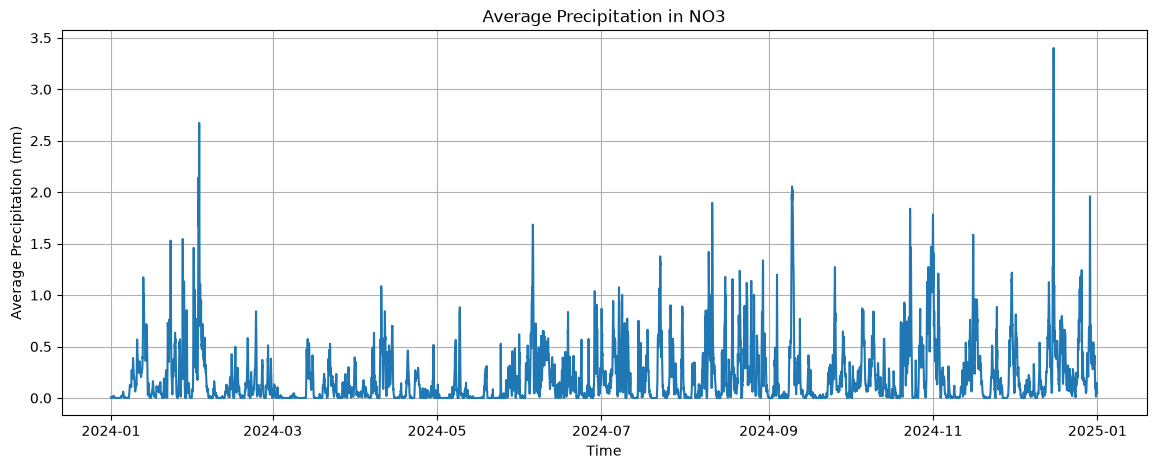

In [36]:
# Plot the average hourly precipitation over time.
plt.figure(figsize=(14, 5))

plt.plot(
    avg_precipitation["time"],
    avg_precipitation["precipitation"]
)

plt.title("Average Precipitation in NO3")
plt.xlabel("Time")
plt.ylabel("Average Precipitation (mm)")
plt.grid(True)

plt.show()

## Precipitation Outlier Detection with DCT and SPC

In [37]:
# Detect precipitation outliers using DCT high-pass filtering
# and robust Statistical Process Control boundaries.
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import dct, idct


def precipitation_spc_analysis(
    weather_df,
    frequency_cutoff=50,
    n_std=3
):
    # Average precipitation across all sampled NO3 locations.
    hourly_avg = (
        weather_df
        .groupby(
            "time",
            as_index=False
        )["precipitation"]
        .mean()
        .sort_values("time")
    )

    values = hourly_avg[
        "precipitation"
    ].to_numpy()

    # Apply the Discrete Cosine Transform.
    coefficients = dct(
        values,
        norm="ortho"
    )

    # Low-frequency component represents the seasonal baseline.
    low_pass_coefficients = np.zeros_like(
        coefficients
    )

    low_pass_coefficients[
        :frequency_cutoff
    ] = coefficients[
        :frequency_cutoff
    ]

    seasonal_baseline = idct(
        low_pass_coefficients,
        norm="ortho"
    )

    # High-pass component gives seasonally adjusted variation.
    high_pass_coefficients = (
        coefficients.copy()
    )

    high_pass_coefficients[
        :frequency_cutoff
    ] = 0

    satv = idct(
        high_pass_coefficients,
        norm="ortho"
    )

    # Robust SPC limits based on median and MAD.
    centre = np.median(
        satv
    )

    mad = np.median(
        np.abs(
            satv - centre
        )
    )

    robust_std = (
        1.4826 * mad
    )

    lower_satv_limit = (
        centre
        - n_std * robust_std
    )

    upper_satv_limit = (
        centre
        + n_std * robust_std
    )

    # Convert SATV limits back to precipitation-scale curves.
    lower_boundary = (
        seasonal_baseline
        + lower_satv_limit
    )

    upper_boundary = (
        seasonal_baseline
        + upper_satv_limit
    )

    outlier_mask = (
        (satv < lower_satv_limit)
        |
        (satv > upper_satv_limit)
    )

    outliers = hourly_avg.loc[
        outlier_mask
    ].copy()

    # Plot original precipitation, SPC boundaries and outliers.
    fig, ax = plt.subplots(
        figsize=(14, 5)
    )

    ax.plot(
        hourly_avg["time"],
        hourly_avg["precipitation"],
        label="Average precipitation"
    )

    ax.plot(
        hourly_avg["time"],
        upper_boundary,
        linestyle="--",
        label="Upper SPC boundary"
    )

    ax.plot(
        hourly_avg["time"],
        lower_boundary,
        linestyle="--",
        label="Lower SPC boundary"
    )

    ax.scatter(
        outliers["time"],
        outliers["precipitation"],
        label="Outliers",
        zorder=3
    )

    ax.set_title(
        "Average NO3 Precipitation with SPC Outliers"
    )

    ax.set_xlabel("Time")
    ax.set_ylabel(
        "Average Precipitation (mm)"
    )

    ax.grid(True)
    ax.legend()

    summary = {
        "number_of_observations": len(
            hourly_avg
        ),
        "number_of_outliers": int(
            outlier_mask.sum()
        ),
        "outlier_percentage": float(
            outlier_mask.mean() * 100
        ),
        "frequency_cutoff": frequency_cutoff,
        "n_std": n_std,
        "lower_satv_limit": lower_satv_limit,
        "upper_satv_limit": upper_satv_limit
    }

    return fig, outliers, summary

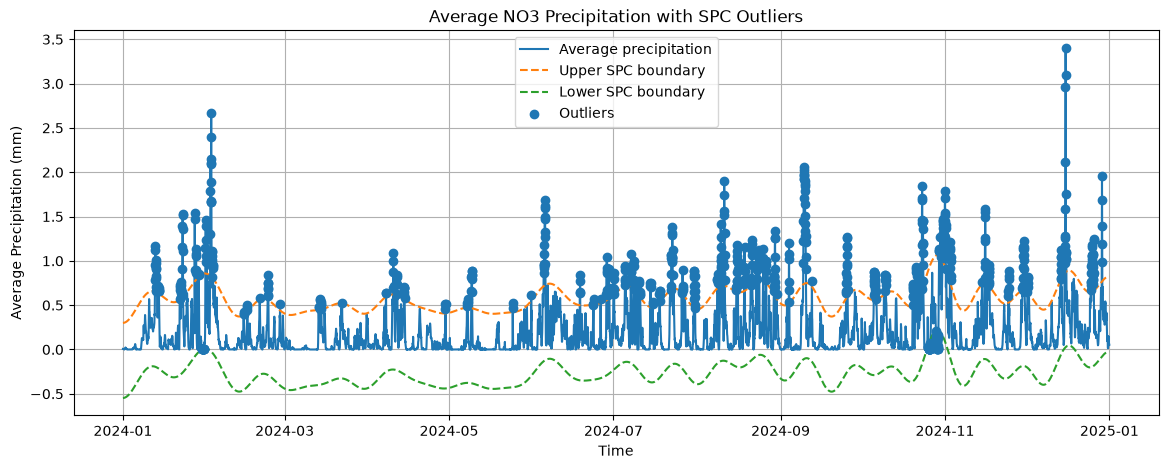

{'number_of_observations': 8784, 'number_of_outliers': 673, 'outlier_percentage': 7.6616575591985425, 'frequency_cutoff': 50, 'n_std': 3, 'lower_satv_limit': np.float64(-0.46971403153642327), 'upper_satv_limit': np.float64(0.3776655367683965)}


,time,precipitation
286,2024-01-12 22:00:00,0.7814
287,2024-01-12 23:00:00,0.9575
288,2024-01-13 00:00:00,1.1731
289,2024-01-13 01:00:00,1.1251
290,2024-01-13 02:00:00,0.9246


In [38]:
precip_fig, precip_outliers, precip_summary = (
    precipitation_spc_analysis(
        no3_weather_2024,
        frequency_cutoff=50,
        n_std=3
    )
)

plt.show()

print(
    precip_summary
)

precip_outliers.head()

The DCT high-pass filter was used to remove low-frequency seasonal
variation from precipitation. Robust SPC limits were calculated from
the median and median absolute deviation of the seasonally adjusted
variation. With a frequency cutoff of 50 and three robust standard
deviations, 673 hourly observations were identified as outliers,
corresponding to approximately 7.66% of the observations.

## Temperature Anomaly Detection with Local Outlier Factor

In [39]:
# Detect temperature anomalies using the Local Outlier Factor method.
# The contamination parameter controls the expected proportion of anomalies.
from sklearn.neighbors import LocalOutlierFactor


def temperature_lof_analysis(
    weather_df,
    contamination=0.01
):
    hourly_avg = (
        weather_df
        .groupby("time", as_index=False)["temperature_2m"]
        .mean()
        .sort_values("time")
    )

    values = hourly_avg[
        ["temperature_2m"]
    ].to_numpy()

    lof = LocalOutlierFactor(
        contamination=contamination
    )

    labels = lof.fit_predict(values)

    anomaly_mask = labels == -1

    anomalies = hourly_avg.loc[
        anomaly_mask
    ].copy()

    fig, ax = plt.subplots(
        figsize=(14, 5)
    )

    ax.plot(
        hourly_avg["time"],
        hourly_avg["temperature_2m"],
        label="Average temperature"
    )

    ax.scatter(
        anomalies["time"],
        anomalies["temperature_2m"],
        label="Anomalies",
        zorder=3
    )

    ax.set_title(
        "Average NO3 Temperature with LOF Anomalies"
    )

    ax.set_xlabel("Time")
    ax.set_ylabel("Average Temperature (°C)")
    ax.grid(True)
    ax.legend()

    summary = {
        "number_of_observations": len(hourly_avg),
        "number_of_anomalies": int(anomaly_mask.sum()),
        "anomaly_percentage": float(
            anomaly_mask.mean() * 100
        ),
        "contamination": contamination
    }

    return fig, anomalies, summary

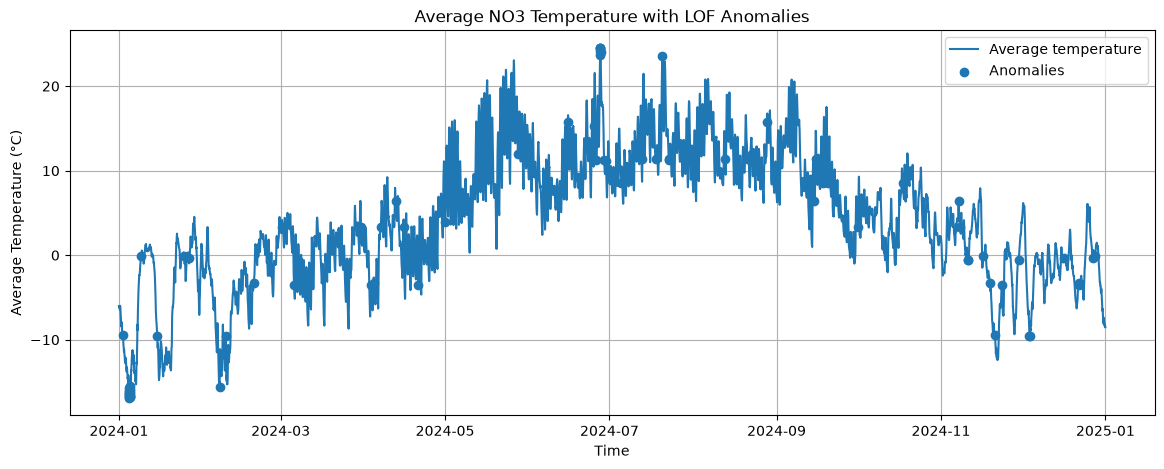

{'number_of_observations': 8784, 'number_of_anomalies': 88, 'anomaly_percentage': 1.0018214936247722, 'contamination': 0.01}


,time,temperature_2m
36,2024-01-02 12:00:00,-9.4811
87,2024-01-04 15:00:00,-15.6766
88,2024-01-04 16:00:00,-16.0356
89,2024-01-04 17:00:00,-16.2028
90,2024-01-04 18:00:00,-16.3634


In [40]:
temperature_fig, temperature_anomalies, temperature_summary = (
    temperature_lof_analysis(
        no3_weather_2024,
        contamination=0.01
    )
)

plt.show()

print(temperature_summary)

temperature_anomalies.head()

Local Outlier Factor was applied to the hourly average temperature
series using an expected anomaly proportion of 1%. The method
identified 88 anomalous observations out of 8,784 hourly observations,
corresponding to approximately 1.00% of the data.

## Reservoir Filling-Level Analysis

In [41]:
# Load reservoir statistics directly from the NVE API
# for the STL and spectrogram analyses.
import requests

nve_url = (
    "https://biapi.nve.no/magasinstatistikk/api/"
    "Magasinstatistikk/HentOffentligData"
)

response = requests.get(
    nve_url,
    timeout=30
)

response.raise_for_status()

reservoir_df = pd.DataFrame(
    response.json()
)

In [42]:
# Rename the NVE variables needed for reservoir analysis.
reservoir_df = reservoir_df.rename(
    columns={
        "dato_Id": "date",
        "omrType": "area_type",
        "omrnr": "area_number",
        "fyllingsgrad": "fill_level"
    }
)

reservoir_df["date"] = pd.to_datetime(
    reservoir_df["date"]
)

reservoir_df.head()

,date,area_type,area_number,iso_aar,iso_uke,fill_level,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
0,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046
1,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694
2,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,0001-01-01T00:00:00,0.733812,0.060157
3,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,0001-01-01T00:00:00,0.311122,-0.010301
4,2017-11-05,EL,4,2017,44,0.794520,21.079208,16.747847,0001-01-01T00:00:00,0.804085,-0.009565


In [43]:
# Select the national reservoir filling-level series.
national_fill = (
    reservoir_df[
        (reservoir_df["area_type"] == "NO")
        &
        (reservoir_df["area_number"] == 0)
    ][["date", "fill_level"]]
    .sort_values("date")
    .dropna()
)

national_fill.head()

,date,fill_level
9941,1995-01-08,0.603830
9885,1995-01-15,0.578233
9848,1995-01-22,0.558350
9822,1995-01-29,0.530596
9887,1995-02-05,0.502755


### STL Decomposition

In [44]:
# Perform STL decomposition on reservoir filling level.
# Seasonal and trend smoother lengths can be adjusted,
# and robust fitting can be enabled or disabled.
from statsmodels.tsa.seasonal import STL


def reservoir_stl_analysis(
    reservoir_data,
    seasonal=53,
    trend=105,
    robust=True
):
    series = (
        reservoir_data
        .set_index("date")["fill_level"]
        .sort_index()
    )

    stl = STL(
        series,
        period=52,
        seasonal=seasonal,
        trend=trend,
        robust=robust
    )

    result = stl.fit()

    fig = result.plot()

    fig.set_size_inches(
        12,
        8
    )

    fig.suptitle(
        "STL Decomposition of National Reservoir Filling Level",
        y=1.02
    )

    return fig, result

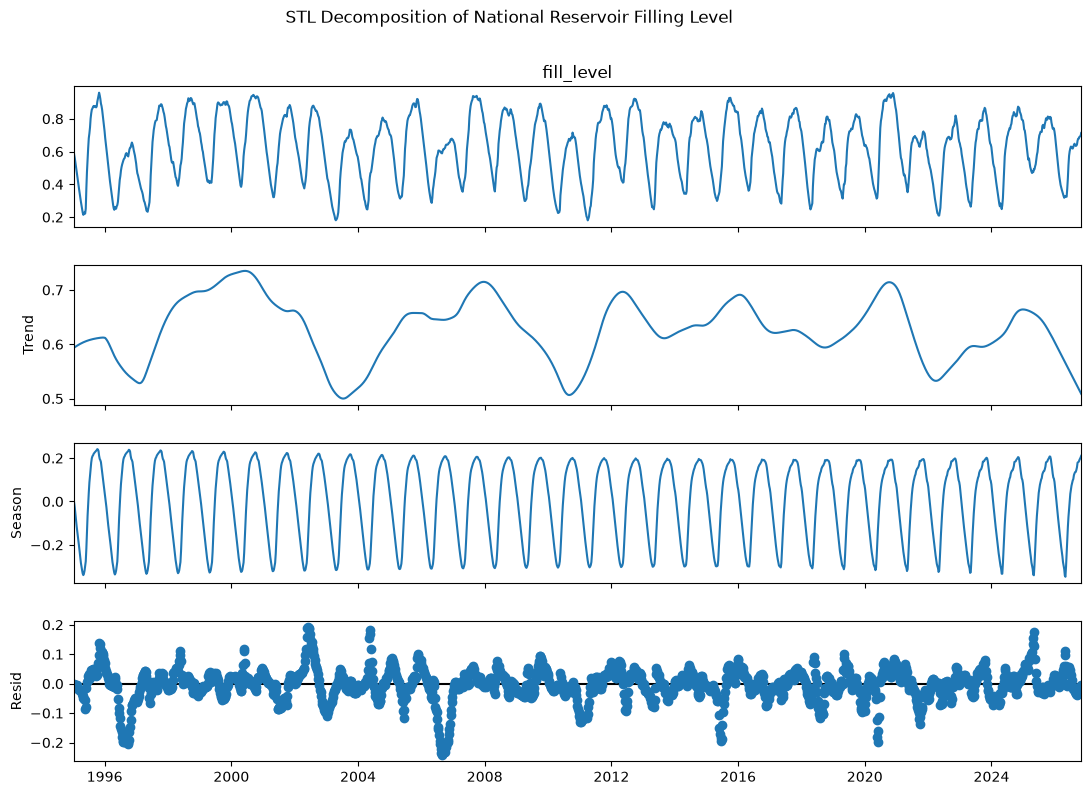

In [45]:
stl_fig, stl_result = reservoir_stl_analysis(
    national_fill,
    seasonal=53,
    trend=105,
    robust=True
)

plt.show()

The STL decomposition separates the reservoir filling-level series into trend, seasonal, and residual components. The seasonal component captures the recurring annual pattern in reservoir levels, while the trend component shows slower long-term changes over time. The residual component contains short-term variation that is not explained by the seasonal or trend components.

Using robust STL fitting helps reduce the influence of unusual observations on the estimated seasonal and trend components. The adjustable seasonal and trend smoothers in the Streamlit application allow the decomposition to be explored under different parameter settings.

### Spectrogram Analysis

In [46]:
# Import the spectrogram function for time-frequency analysis.
from scipy.signal import spectrogram

In [47]:
# Create a spectrogram of reservoir filling level.
# Window length and overlap can be adjusted.
def reservoir_spectrogram(
    reservoir_data,
    window_length=104,
    window_overlap=52
):
    series = (
        reservoir_data
        .set_index("date")["fill_level"]
        .sort_index()
    )

    values = series.to_numpy()

    frequencies, times, power = spectrogram(
        values,
        fs=1,
        nperseg=window_length,
        noverlap=window_overlap
    )

    fig, ax = plt.subplots(
        figsize=(12, 6)
    )

    mesh = ax.pcolormesh(
        times,
        frequencies,
        power,
        shading="auto"
    )

    ax.set_title(
        "Spectrogram of National Reservoir Filling Level"
    )

    ax.set_xlabel("Time")
    ax.set_ylabel("Frequency (cycles per week)")

    fig.colorbar(
        mesh,
        ax=ax,
        label="Power"
    )

    return fig, {
        "frequencies": frequencies,
        "times": times,
        "power": power
    }

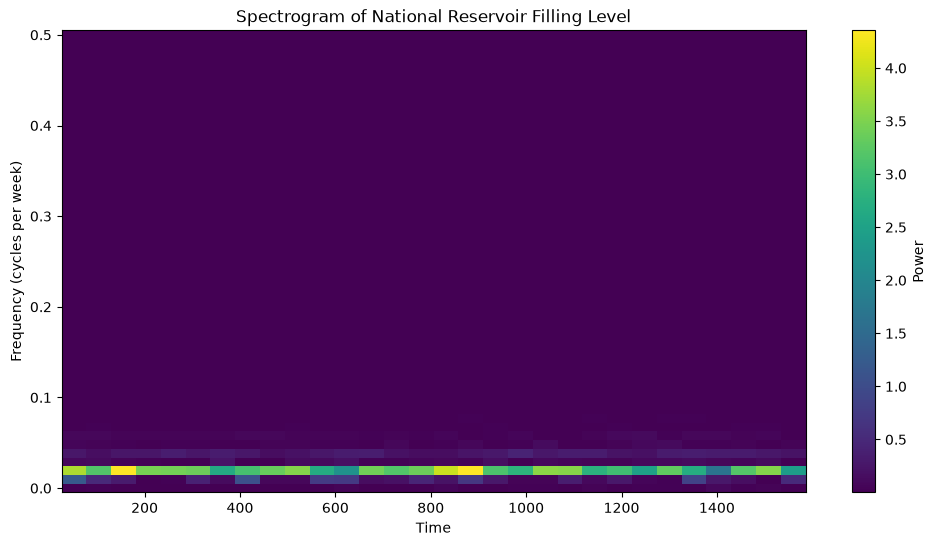

In [48]:
spectrogram_fig, spectrogram_result = (
    reservoir_spectrogram(
        national_fill,
        window_length=104,
        window_overlap=52
    )
)

plt.show()

The spectrogram shows how the frequency content of the reservoir filling-level series changes over time. Stronger regions in the spectrogram indicate frequencies that contribute more strongly during particular time periods.

Because reservoir levels have recurring seasonal behaviour, low-frequency components are expected to be important. The spectrogram complements the STL decomposition by showing how periodic behaviour changes through time rather than separating the series directly into trend, seasonal, and residual components.

The Streamlit application allows the window length and overlap to be adjusted so that the trade-off between time resolution and frequency resolution can be explored interactively.

## Development Log

For Part 3 of ReservoirScope, I extended the project with geographical sampling, historical weather data, anomaly detection, and additional time-series analysis. I continued development on the `part3-development` branch so that the new work remained separate from the main branch during development and review.

I first obtained geographical polygon data for Norwegian electricity bidding areas and NVE regions. The polygons were projected to a metric coordinate reference system before random sampling. I generated 1,000 random locations inside each electricity bidding area (NO1–NO5). I also created the broader weather regions required for Magasinstatistikk by combining RS and RØ as East, using RV as West, and combining RM and RN as North. The sampled coordinates were converted back to WGS84 latitude and longitude for use with Open-Meteo.

I implemented a reusable function for downloading historical ERA5 weather data from the Open-Meteo API. The function accepts a region identifier and date interval and retrieves hourly temperature and precipitation. During development I encountered API rate-limit errors, so I added retry and backoff logic, downloaded NO3 data month by month, and saved completed months as Parquet files. API requests were also changed to pool 100 latitude/longitude pairs per request. The complete NO3 dataset for 2024 contains 8,784,000 location-level hourly observations, aggregated into 8,784 hourly regional observations.

For precipitation analysis, I used a Discrete Cosine Transform high-pass filter to obtain seasonally adjusted variation. Robust Statistical Process Control limits were calculated using the median and median absolute deviation, and observations outside the limits were highlighted as outliers. Temperature anomalies were detected using Local Outlier Factor with a default expected anomaly proportion of 1%.

I also added STL decomposition and spectrogram analysis for reservoir filling levels, with adjustable parameters in Streamlit. Feedback from Part 2 was incorporated by adding a custom date range to the `LineChartColumn` table, plotting all area numbers for the selected NVE area type, and removing the old `reservoirs.csv` file so reservoir data is retrieved directly from the NVE API.

Finally, I added two new tab-based pages: Seasonal Analysis and Weather Outliers and Anomalies. The weather page retrieves ERA5 data directly from Open-Meteo using EL, NO, or VASS geographical selections, while the seasonal page provides STL and spectrogram analysis. I also updated the application navigation, project information, dependencies, and supporting data files for Part 3.

## Use of Generative AI

Generative AI was used as a support tool during the development of Part 3 of ReservoirScope. I used ChatGPT mainly for debugging, code organisation, reviewing assignment requirements, and improving the structure of Python and Streamlit code.

AI assistance was particularly useful when diagnosing Open-Meteo API rate-limit errors, restructuring the weather download workflow, and adding retry and backoff handling. It was also used to review the geographical sampling workflow, improve the DCT/SPC and Local Outlier Factor implementations, and organise the STL and spectrogram functionality for the Streamlit application.

ChatGPT was also used to compare the implementation against the assignment requirements and identify missing elements such as SPC boundary curves, Streamlit region selection, project documentation, and deployment dependencies.

All generated suggestions were reviewed before being used. I tested the code locally, checked outputs, corrected errors, and adapted the implementation to match the project structure and course requirements. The final code, analysis, parameter choices, and interpretation of the results were therefore verified and integrated by me rather than being used without review.

## Project Links

- GitHub: https://github.com/Zawaril/ReservoirScope
- Streamlit: https://reservoirscope.streamlit.app/